In [65]:
import pandas as pd 
from stratified_dataset import question_scorer
import os
import numpy as np

# TOTAL ACC

In [66]:
pred = pd.read_csv("results.csv").rename(columns = {'final_answer' : 'system output'})
val = pd.read_json("stratified_dataset/60_task_subset_val.json")

#results dataframe
res =pd.merge(pred,val[['Final answer', 'task_id','Level']], on="task_id")

accuracy_list = []
for idx, row in res.iterrows():
    sys_out = str(row['system output']) if pd.notna(row['system output']) else "None"
    gt = row['Final answer']
    try:
        passed = question_scorer(model_answer=sys_out, ground_truth=gt)
    except Exception as e:
        passed = False

    accuracy_list.append({
        'task_id': row['task_id'],
        'Level': row['Level'],
        'config_id': row['config_id'],
        'passed': passed
    })

accuracy_df = pd.DataFrame(accuracy_list)

conf_accuracy_results = []
for i in range(1,10):
    df = accuracy_df[accuracy_df['config_id'] == i]

    lvl1 = df[df['Level'] == 1].passed.value_counts()[True]
    lvl2 = df[df['Level'] == 2].passed.value_counts()[True]
    conf_accuracy_results.append(
        {
            'config_id' : i,
            'lvl1_passed' : lvl1,
            'lvl2_passed' : lvl2,
            'total_passed_percentage' : round(((lvl1 + lvl2) /len(df)) * 100 , 2)
        }
    )
conf_accuracy_results = pd.DataFrame(conf_accuracy_results)
conf_accuracy_results

Evaluating cornstarch, granulated sugar, lemon juice, ripe strawberries, vanilla extract as a comma separated list.
Evaluating 1 as a number.
Evaluating 89706.00 as a number.
Evaluating Bartek as a string.
Evaluating sklearn.utils.metaestimators as a string.
Evaluating 90 as a number.
Evaluating 0 as a number.
Evaluating Honolulu, Hawaii, Scranton, Pennsylvania as a comma separated list.
Evaluating 80GSFC21M0002 as a string.
Evaluating Annie Levin as a string.
Evaluating (A → B) ↔ (¬A ∨ B) as a string.
Evaluating 0.1777 as a number.
Evaluating 3/4,1/4,3/4,2/4,1/2,5/35,7/21,30/5,1/2,6/9,5/90,30/90,4/14,5/15,7/21,6/61,61/60,20/30 as a comma separated list.
Evaluating None as a string.
Evaluating 500 Things To Eat Before It's Too Late: and the Very Best Places to Eat Them as a string.
Evaluating 4 as a number.
Evaluating 519 as a number.
Evaluating 27 as a number.
Evaluating 12 as a number.
Evaluating Guatemala as a string.
Evaluating 3 as a number.
Evaluating 197, 245 as a comma separate

/home/mike/Projects/clef-vs-qwen-orch/harness/stratified_dataset/official_gaia_scorer.py:56: UserWarning: Answer lists have different lengths, returning False.
  warnings.warn(


,config_id,lvl1_passed,lvl2_passed,total_passed_percentage
0,1,15,4,31.67
1,2,15,3,30.00
2,3,15,3,30.00
3,4,14,5,31.67
4,5,13,6,31.67
5,6,14,5,31.67
6,7,9,4,21.67
7,8,15,5,33.33
8,9,16,4,33.33


# ANALYSING LOGS

In [67]:
all_dfs = []
for conf in range(1, 10):
    folder_path = f"results/mas_{conf}"
    for filename in sorted(os.listdir(folder_path)):
        if filename.endswith(".csv"):
            file_path = os.path.join(folder_path, filename)
            df_task = pd.read_csv(file_path)
            df_task["config_id"] = conf
            all_dfs.append(df_task)
master_df = pd.concat(all_dfs)
master_df.head()

,task_id,node,subagent_steps,state_step,tool_name,tool_args,confidence,probabilities,reasoning,compute_time_seconds,llm_tkns_in,llm_tkns_out,fdm_tkns_in,fdm_tkns_out,response,error,config_id
0,023e9d44-96ae-4eed-b912-244ee8c3b994,orchestrator,NaN,1,NaN,NaN,0.6666,"{'web_search': 0.8521, 'doc_reader': 0.0249, '...",NaN,0.764450,0,0,571,0,web_search,NaN,1
1,023e9d44-96ae-4eed-b912-244ee8c3b994,web_search,1.0,2,wikipedia_tool,"{""query"": ""bottle deposit refund law United St...",NaN,NaN,NaN,1.661684,1102,31,0,0,Page: Container deposit legislation in the Uni...,NaN,1
2,023e9d44-96ae-4eed-b912-244ee8c3b994,web_search,2.0,2,wikipedia_tool,"{""query"": ""California bottle deposit refund am...",NaN,NaN,NaN,1.665394,1838,29,0,0,Page: Container-deposit legislation\nSummary: ...,NaN,1
3,023e9d44-96ae-4eed-b912-244ee8c3b994,web_search,3.0,2,readable_webpage,"{""url"": ""https://en.wikipedia.org/wiki/Califor...",NaN,NaN,NaN,1.770710,2397,36,0,0,# California Redemption Value\n\nFee on recycl...,NaN,1
4,023e9d44-96ae-4eed-b912-244ee8c3b994,web_search,4.0,2,wikipedia_tool,"{""query"": ""Maine bottle deposit refund amount""}",NaN,NaN,NaN,2.758252,5649,30,0,0,Page: Container-deposit legislation\nSummary: ...,NaN,1


In [68]:
task_id_list = master_df.task_id.unique()
config_id_list = master_df.config_id.unique()
summary_records = []

for config in config_id_list:
    conf_df = master_df[master_df.config_id == config]

    task_latencies = []
    orch_latencies = []
    subagent_latencies = []
    task_llm_in = []
    task_llm_out = []
    task_fdm_in = []
    task_fdm_out = []
    task_state_steps = []
    task_subagent_steps = []

    for task in task_id_list:
        #x is the sub df for the given task in a given config
        x = conf_df[conf_df.task_id == task]

        #total Latency per task
        task_latencies.append(x.compute_time_seconds.sum())
        #orch Latency (node == 'orchestrator')
        orch_latencies.append(
            x[x.node == "orchestrator"].compute_time_seconds.sum()
        )
        #subagent Latency (node != 'orchestrator')
        subagent_latencies.append(
            x[x.node != "orchestrator"].compute_time_seconds.sum()
        )
        #tokens per task
        task_llm_in.append(x.llm_tkns_in.sum())
        task_llm_out.append(x.llm_tkns_out.sum())
        task_fdm_in.append(x.fdm_tkns_in.sum())
        task_fdm_out.append(x.fdm_tkns_out.sum())
        #state_step  is the orchestrator steps
        task_state_steps.append(x.state_step.max())
        # count subagent_steps
        task_subagent_steps.append(x.subagent_steps.notna().sum())
    

    #tool Error Rate per config
    
    has_error = conf_df.error.notna()
    
    total_steps = len(conf_df)
    total_errors = has_error.sum()
    general_error_rate = (total_errors / total_steps * 100)
    summary_records.append(
        {
            "config_id": config,

            "mean_total_latency_s": np.mean(task_latencies),
            "mean_orch_latency_s": np.mean(orch_latencies),
            "mean_subagent_latency_s": np.mean(subagent_latencies),
            
            "mean_llm_in_tokens": np.mean(task_llm_in),
            "mean_llm_out_tokens": np.mean(task_llm_out),
            "mean_fdm_in_tokens": np.mean(task_fdm_in),
            "mean_fdm_out_tokens": np.mean(task_fdm_out),

            "mean_state_steps": np.mean(task_state_steps),
            "mean_subagent_steps": np.mean(task_subagent_steps),

            "general_error_rate_pct": general_error_rate,
        }
    )
metrics_df = pd.DataFrame(summary_records)
metrics_df = pd.merge(metrics_df, conf_accuracy_results)

# COST IN CENTS

In [69]:
PRICE_LLM_IN = 0.08 / 1000000
PRICE_LLM_OUT = 0.13 / 1000000
PRICE_FDM_IN = 0.038 / 1000000


metrics_df["mean_llm_cost"] = (
    metrics_df["mean_llm_in_tokens"] * PRICE_LLM_IN
    + metrics_df["mean_llm_out_tokens"] * PRICE_LLM_OUT
) * 100
metrics_df["mean_fdm_cost"] = metrics_df["mean_fdm_in_tokens"] * PRICE_FDM_IN * 100
metrics_df["mean_cost"] = (
    metrics_df["mean_llm_cost"] + metrics_df["mean_fdm_cost"]
) 

metrics_df["total_benchmark_cost"] = metrics_df["mean_cost"] * 60

metrics_df["acc_per_min"] = (metrics_df["total_passed_percentage"] / metrics_df["mean_total_latency_s"]) * 60
metrics_df["acc_per_cent"] = metrics_df["total_passed_percentage"] / metrics_df["mean_cost"]

In [70]:
metrics_df.round(2)

,config_id,mean_total_latency_s,mean_orch_latency_s,mean_subagent_latency_s,mean_llm_in_tokens,mean_llm_out_tokens,mean_fdm_in_tokens,mean_fdm_out_tokens,mean_state_steps,mean_subagent_steps,general_error_rate_pct,lvl1_passed,lvl2_passed,total_passed_percentage,mean_llm_cost,mean_fdm_cost,mean_cost,total_benchmark_cost,acc_per_min,acc_per_cent
0,1,55.51,1.98,53.53,44645.00,1243.33,1817.47,0.0,3.62,8.82,3.49,15,4,31.67,0.37,0.01,0.38,22.81,34.23,83.29
1,2,66.59,4.91,61.68,56601.73,1194.70,0.00,0.0,3.68,9.78,3.71,15,3,30.00,0.47,0.00,0.47,28.10,27.03,64.06
2,3,137.15,32.00,105.15,60193.68,3294.85,0.00,0.0,3.47,9.15,3.30,15,3,30.00,0.52,0.00,0.52,31.46,13.12,57.21
3,4,398.24,5.23,393.01,56704.92,12831.37,39995.25,0.0,4.48,13.97,21.32,14,5,31.67,0.62,0.15,0.77,46.35,4.77,41.00
4,5,73.35,3.63,69.72,33520.87,1320.02,25719.83,0.0,3.67,9.98,12.45,13,6,31.67,0.29,0.10,0.38,22.98,25.91,82.68
5,6,91.53,5.57,85.96,28649.62,2444.28,0.00,0.0,4.92,8.78,0.61,14,5,31.67,0.26,0.00,0.26,15.66,20.76,121.35
6,7,155.14,1.78,153.36,59151.75,4243.37,39624.70,0.0,4.03,12.53,13.08,9,4,21.67,0.53,0.15,0.68,40.74,8.38,31.92
7,8,136.46,46.47,89.99,34931.63,4372.17,0.00,0.0,4.92,10.02,1.79,15,5,33.33,0.34,0.00,0.34,20.18,14.65,99.11
8,9,115.33,3.60,111.73,42584.58,2881.45,2828.57,0.0,5.65,13.35,0.79,16,4,33.33,0.38,0.01,0.39,23.33,17.34,85.71


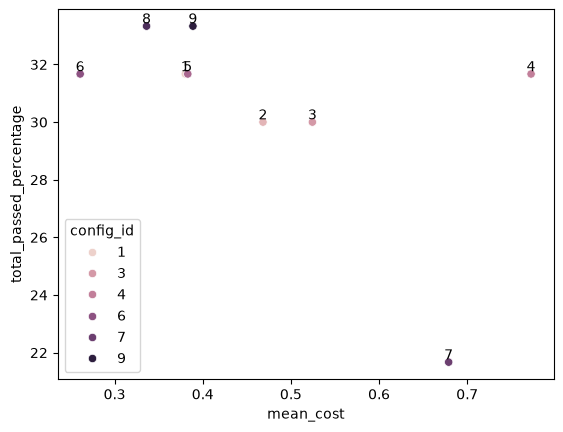

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.scatterplot(data=metrics_df, x="mean_cost", y="total_passed_percentage", hue="config_id")
for _, row in metrics_df.iterrows():
    ax.annotate(
        text=str(int(row["config_id"])),
        xy=(row["mean_cost"], row["total_passed_percentage"]),
        xytext=(0, 2),  
        textcoords="offset points",
        ha="center",  
    )
    

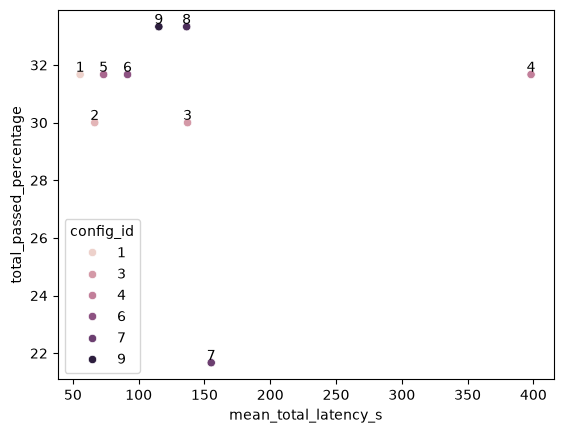

In [72]:
ax = sns.scatterplot(data=metrics_df, x="mean_total_latency_s", y="total_passed_percentage", hue= "config_id")
for _, row in metrics_df.iterrows():
    ax.annotate(
        text=str(int(row["config_id"])),
        xy=(row["mean_total_latency_s"], row["total_passed_percentage"]),
        xytext=(0, 2),  
        textcoords="offset points",
        ha="center",  
    )
plt.show()


# BEST ORCH

   config_id  total_passed_percentage  mean_cost  mean_total_latency_s  \
0          1                    31.67       0.38                 55.51   
1          2                    30.00       0.47                 66.59   
2          3                    30.00       0.52                137.15   

   acc_per_min  acc_per_cent  
0        34.23         83.29  
1        27.03         64.06  
2        13.12         57.21  


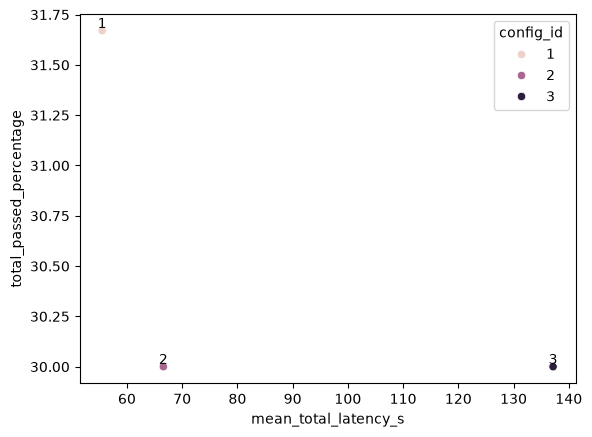

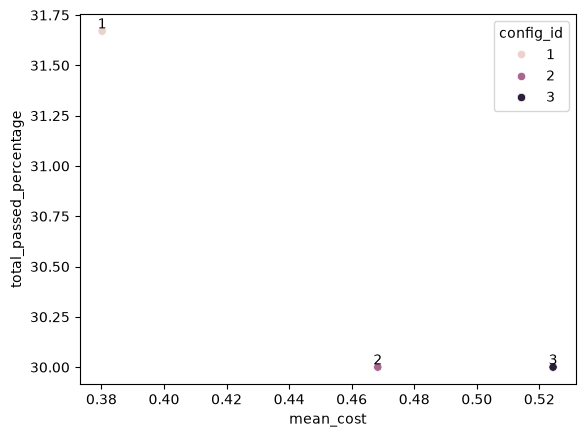

In [81]:

df_reordered = metrics_df[metrics_df.config_id  <=3].iloc[:, [0,13,16,1, 18, 19 ]]
print(df_reordered.round(2))
ax = sns.scatterplot(data=df_reordered, x="mean_total_latency_s", y="total_passed_percentage", hue= "config_id")
for _, row in df_reordered.iterrows():
    ax.annotate(
        text=str(int(row["config_id"])),
        xy=(row["mean_total_latency_s"], row["total_passed_percentage"]),
        xytext=(0, 2),  
        textcoords="offset points",
        ha="center",  
    )
plt.show()

ax = sns.scatterplot(data=df_reordered, x="mean_cost", y="total_passed_percentage", hue="config_id")
for _, row in df_reordered.iterrows():
    ax.annotate(
        text=str(int(row["config_id"])),
        xy=(row["mean_cost"], row["total_passed_percentage"]),
        xytext=(0, 2),  
        textcoords="offset points",
        ha="center",  
    )
    

# BEST SUBAGENT

   config_id  total_passed_percentage  mean_cost  mean_total_latency_s  \
1          2                    30.00       0.47                 66.59   
3          4                    31.67       0.77                398.24   
4          5                    31.67       0.38                 73.35   
5          6                    31.67       0.26                 91.53   

   acc_per_min  acc_per_cent  
1        27.03         64.06  
3         4.77         41.00  
4        25.91         82.68  
5        20.76        121.35  


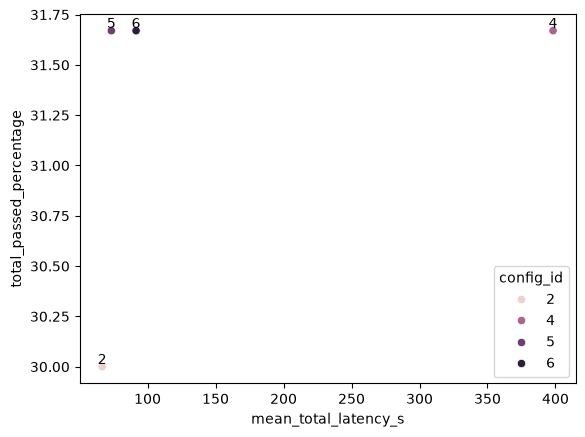

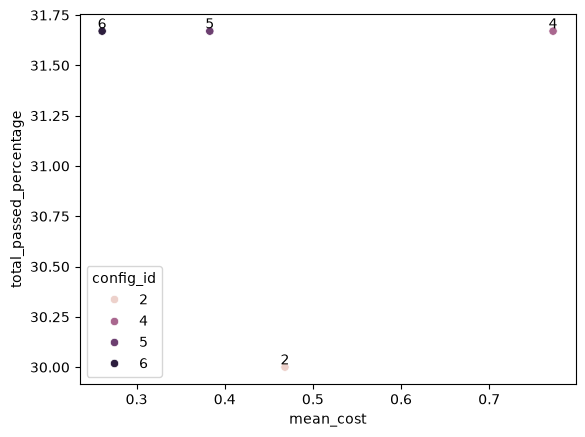

In [82]:
df_reordered = metrics_df[metrics_df.config_id.isin([2,4,5,6])].iloc[:, [0,13,16,1, 18, 19 ]]
print(df_reordered.round(2))
ax = sns.scatterplot(data=df_reordered, x="mean_total_latency_s", y="total_passed_percentage", hue= "config_id")
for _, row in df_reordered.iterrows():
    ax.annotate(
        text=str(int(row["config_id"])),
        xy=(row["mean_total_latency_s"], row["total_passed_percentage"]),
        xytext=(0, 2),  
        textcoords="offset points",
        ha="center",  
    )
plt.show()

ax = sns.scatterplot(data=df_reordered, x="mean_cost", y="total_passed_percentage", hue="config_id")
for _, row in df_reordered.iterrows():
    ax.annotate(
        text=str(int(row["config_id"])),
        xy=(row["mean_cost"], row["total_passed_percentage"]),
        xytext=(0, 2),  
        textcoords="offset points",
        ha="center",  
    )
    

# FULL FDM (THINKING) VS FULL LLM (THINKING) VS FDM-LLM(THINKING)


   config_id  total_passed_percentage  mean_cost  mean_total_latency_s  \
6          7                    21.67       0.68                155.14   
7          8                    33.33       0.34                136.46   
8          9                    33.33       0.39                115.33   

   acc_per_min  acc_per_cent  
6         8.38         31.92  
7        14.65         99.11  
8        17.34         85.71  


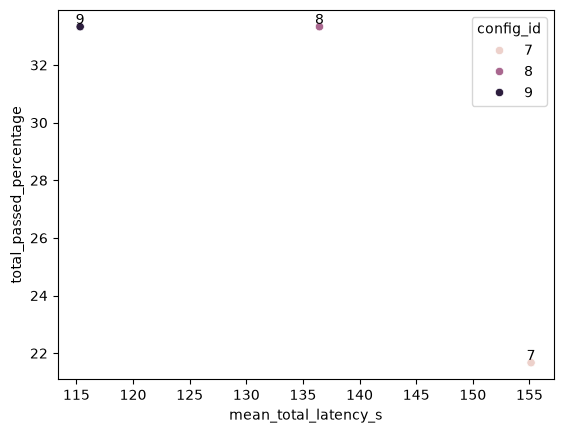

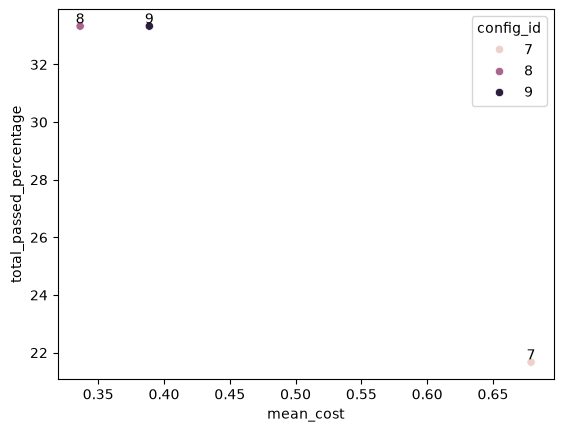

In [83]:
df_reordered = metrics_df[metrics_df.config_id.isin([7,8,9])].iloc[:, [0,13,16,1, 18, 19 ]]
print(df_reordered.round(2))
ax = sns.scatterplot(data=df_reordered, x="mean_total_latency_s", y="total_passed_percentage", hue= "config_id")
for _, row in df_reordered.iterrows():
    ax.annotate(
        text=str(int(row["config_id"])),
        xy=(row["mean_total_latency_s"], row["total_passed_percentage"]),
        xytext=(0, 2),  
        textcoords="offset points",
        ha="center",  
    )
plt.show()

ax = sns.scatterplot(data=df_reordered, x="mean_cost", y="total_passed_percentage", hue="config_id")
for _, row in df_reordered.iterrows():
    ax.annotate(
        text=str(int(row["config_id"])),
        xy=(row["mean_cost"], row["total_passed_percentage"]),
        xytext=(0, 2),  
        textcoords="offset points",
        ha="center",  
    )
    